# Experiment 05: Optimizers

Card: [exp05_optimizers.md](../../experiments/exp05_optimizers.md)


In [4]:
from functools import partial
import os
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import FOLDS
from ashrae.plots import INK, MUTED, SURFACE, TEXT, style_axis
from src.data import fold_loaders
from src.networks import MeterMLP
from src.optim import OPTIMIZERS
from src.runs import finished_keys, fold_table, scores_at_best, session_scores
from src.tracking import Experiment
from src.training import fit_folds

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp05_optimizers"
EMB_DIM = 12  # picked in exp03
if SMOKE:
    EXPERIMENT = "ashrae-mlp-optimizers-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS, WINDOW = 3, 1
    LRS = {
        "Adam": [3e-4, 1e-3, 3e-3, 1e-2],
        "Momentum": [3e-3, 1e-2, 3e-2, 1e-1],
        "Nesterov": [3e-3, 1e-2, 3e-2, 1e-1],
    }
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-optimizers"
    TRAIN = False  # trained in the session below; True trains only runs it lacks
    SESSION = "2026-10-12 13:42:10"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40  # Momentum and Nesterov converge slowly
    WINDOW = (
        5  # epochs before the best one over which the epoch-to-epoch change is averaged
    )
    LRS = {
        "Adam": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2],
        "Momentum": [1e-3, 3e-3, 1e-2, 3e-2, 1e-1],
        "Nesterov": [1e-3, 3e-3, 1e-2, 3e-2, 1e-1],
    }
    FIGURE = "../../figures/exp05_optimizers.png"
# the first and last rate of each grid are trained only if the best inner rate is next to them

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-optimizers', session 2026-10-12 13:42:10


## Training


In [5]:
def at_best(run_id):
    """`scores_at_best`, plus the mean change of validation RMSLE per epoch over the WINDOW epochs up to the best."""
    s = scores_at_best(experiment, run_id)
    if np.isfinite(s["val"]):
        b = s["best_epoch"] - 1
        val = s["val_curve"]
        s["change"] = np.abs(np.diff(val[max(b - WINDOW, 0) : b + 1])).mean() if b else np.nan
    else:
        s.update(best_epoch=np.nan, val_clean=np.inf, train=np.inf, change=np.nan)
    return s


def scores():
    return session_scores(experiment, {"optimizer": str, "lr": float}, FOLD_NAMES, at_best=at_best)

In [6]:
if TRAIN:
    folds, n_buildings, n_features = fold_loaders(FOLD_NAMES, N_TRAIN, N_VAL)
    done = set() if SESSION is None else finished_keys(scores(), ["optimizer", "lr", "fold"])

    def train(optimizer, lr):
        fit_folds(
            experiment,
            folds,
            lambda: MeterMLP(n_features, n_buildings, emb_dim=EMB_DIM),
            f"mlp_4out_emb | {optimizer} lr {lr:g}",
            done=done,
            key=(optimizer, lr),
            epochs=EPOCHS,
            lr=lr,  # recorded only: the optimizer below sets the rate
            optimizer=partial(OPTIMIZERS[optimizer], lr=lr),
            tags={"model": "mlp_4out_emb", "optimizer": optimizer, "lr": f"{lr:g}"},
            params={"n_train": N_TRAIN, "n_val": N_VAL, "emb_dim": EMB_DIM},
        )

    for optimizer, lrs in LRS.items():
        for lr in lrs[1:-1]:
            train(optimizer, lr)
    grid = scores()
    for optimizer, lrs in LRS.items():
        inner = grid[(grid.optimizer == optimizer) & grid.lr.isin(lrs[1:-1])]
        best = inner.groupby("lr").val.mean().idxmin()
        if best == lrs[1]:
            train(optimizer, lrs[0])
        elif best == lrs[-2]:
            train(optimizer, lrs[-1])

## Results


In [7]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs")

columns = {
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training",
    "change": "epoch-to-epoch change",
}
table, by_lr = fold_table(results, ["optimizer", "lr"], columns, FOLD_NAMES)
table = table.loc[list(OPTIMIZERS)]
display(table.round(3))

best_lr = {o: by_lr.loc[o].val.idxmin() for o in OPTIMIZERS}
display(
    table.loc[list(best_lr.items())]
    .round(3)
    .rename_axis(columns="each optimizer at its best lr")
)

MLflow session 2026-10-12 13:42:10: 48 runs


RMSLE at the best epoch, all rows unless noted  Jan–Mar  Apr–Jun  Jul–Sep  \
optimizer lr                                                                
Adam      0.0003                                  1.415    1.219    1.043   
          0.0010                                  1.407    1.210    1.025   
          0.0030                                  1.402    1.205    1.020   
          0.0100                                  1.399    1.204    1.011   
Momentum  0.0030                                  1.430    1.238    1.103   
          0.0100                                  1.408    1.222    1.072   
          0.0300                                  1.407    1.222    1.053   
          0.1000                                  1.421    1.222    1.058   
Nesterov  0.0030                                  1.433    1.240    1.109   
          0.0100                                  1.416    1.231    1.062   
          0.0300                                  1.403    1.223    1.052   
          0.1000                                  1.411    1.217    1.052   

RMSLE at the best epoch, all rows unless noted  Oct–Dec  average  \
optimizer lr                                                       
Adam      0.0003                                  1.101    1.194   
          0.0010                                  1.099    1.185   
          0.0030                                  1.095    1.180   
          0.0100                                  1.090    1.176   
Momentum  0.0030                                  1.122    1.223   
          0.0100                                  1.110    1.203   
          0.0300                                  1.104    1.197   
          0.1000                                  1.111    1.203   
Nesterov  0.0030                                  1.127    1.227   
          0.0100                                  1.110    1.205   
          0.0300                                  1.107    1.196   
          0.1000                                  1.106    1.197   

RMSLE at the best epoch, all rows unless noted  average, clean rows  \
optimizer lr                                                          
Adam      0.0003                                              0.931   
          0.0010                                              0.923   
          0.0030                                              0.920   
          0.0100                                              0.913   
Momentum  0.0030                                              0.973   
          0.0100                                              0.953   
          0.0300                                              0.943   
          0.1000                                              0.958   
Nesterov  0.0030                                              0.978   
          0.0100                                              0.951   
          0.0300                                              0.946   
          0.1000                                              0.940   

RMSLE at the best epoch, all rows unless noted  best epoch  training  \
optimizer lr                                                           
Adam      0.0003                                     38.75     0.817   
          0.0010                                     35.25     0.797   
          0.0030                                     23.50     0.790   
          0.0100                                     29.00     0.773   
Momentum  0.0030                                     39.50     0.863   
          0.0100                                     36.75     0.839   
          0.0300                                     30.75     0.830   
          0.1000                                     29.25     0.842   
Nesterov  0.0030                                     38.50     0.864   
          0.0100                                     39.50     0.834   
          0.0300                                     32.75     0.825   
          0.1000                     

,each optimizer at its best lr,Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,"average, clean rows",best epoch,training,epoch-to-epoch change
optimizer,lr,,,,,,,,,
Adam,0.01,1.399,1.204,1.011,1.090,1.176,0.913,29.00,0.773,0.007
Momentum,0.03,1.407,1.222,1.053,1.104,1.197,0.943,30.75,0.830,0.008
Nesterov,0.03,1.403,1.223,1.052,1.107,1.196,0.946,32.75,0.825,0.014


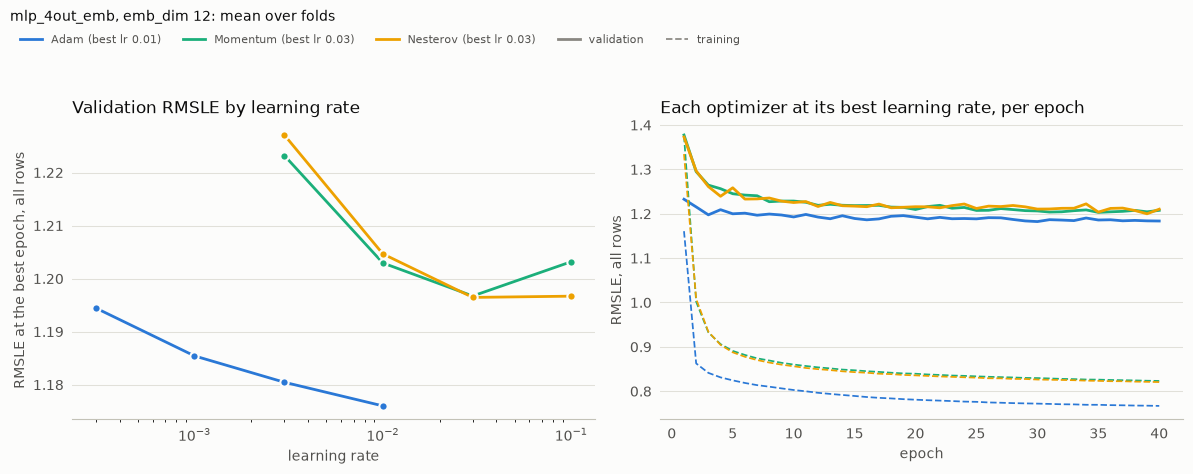

In [8]:
COLORS = dict(zip(OPTIMIZERS, ["#2a78d6", "#1baf7a", "#eda100"]))
epochs = np.arange(1, EPOCHS + 1)

fig, (ax_lr, ax_ep) = plt.subplots(1, 2, figsize=(12, 4.6), facecolor=SURFACE)
for optimizer, color in COLORS.items():
    curve = by_lr.loc[optimizer].val
    ax_lr.plot(
        curve.index, curve, color=color, lw=2, marker="o", ms=6, mec=SURFACE, mew=1.5
    )
    runs = results[
        (results.optimizer == optimizer) & (results.lr == best_lr[optimizer])
    ]
    for key, ls in [("val_curve", "-"), ("train_curve", "--")]:
        ax_ep.plot(
            epochs,
            np.mean(runs[key].tolist(), axis=0),
            color=color,
            lw=2 if ls == "-" else 1.25,
            ls=ls,
        )
ax_lr.set(
    xscale="log", xlabel="learning rate", ylabel="RMSLE at the best epoch, all rows"
)
ax_lr.set_title("Validation RMSLE by learning rate", loc="left", color=INK)
ax_ep.set(xlabel="epoch", ylabel="RMSLE, all rows")
ax_ep.set_title(
    "Each optimizer at its best learning rate, per epoch", loc="left", color=INK
)
for ax in (ax_lr, ax_ep):
    style_axis(ax)
handles = [
    *(
        Line2D([], [], color=c, lw=2, label=f"{o} (best lr {best_lr[o]:g})")
        for o, c in COLORS.items()
    ),
    Line2D([], [], color=MUTED, lw=2, label="validation"),
    Line2D([], [], color=MUTED, lw=1.25, ls="--", label="training"),
]
fig.legend(
    handles=handles,
    ncol=5,
    frameon=False,
    fontsize=8,
    labelcolor=TEXT,
    loc="lower left",
    bbox_to_anchor=(0.01, 0.92),
)
fig.suptitle(
    f"mlp_4out_emb, emb_dim {EMB_DIM}: mean over folds",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
    y=1.02,
)
plt.tight_layout(rect=(0, 0, 1, 0.92))
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.run_id:
        experiment.client.log_artifact(run_id, FIGURE)